# Bank Account Fraud (BAF) - Evaluation and Fairness

Steps covered in this notebook:

1. **Load data and models** - the preprocessed validation sets from `02_preprocessing_and_baselines` and the baseline and tuned models saved by `03_hyperparameter_tuning`.
2. **Baseline vs tuned** - score every model on validation month 7 at the 5% FPR threshold and compare them in a results table and on ROC / precision-recall curves.
3. **Remove age** - retrain both tuned models without `customer_age` (the protected attribute), keeping their tuned hyperparameters.
4. **Fairness comparison** - compare performance and false positive rates across age groups for the models with and without age.
5. **MLflow** - optionally log the retrained models and the fairness comparison.

Run `03_hyperparameter_tuning` first, so `../models/` holds the trained models.

In [1]:
import json
from pathlib import Path

import pandas as pd
import numpy as np

import joblib
import matplotlib.pyplot as plot

from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

import mlflow
import mlflow.sklearn
from mlflow.models.signature import infer_signature

In [2]:
# True logs the retrained no-age models and the fairness comparison (needs the MLflow server at localhost:5000)
LOG_TO_MLFLOW = False
XGB_DEVICE = "cuda"  # device for retraining XGBoost without age; 'cpu' also works

## Load Data and Models

The same preprocessed data the models were trained on. Ages for the fairness metrics come from the XGBoost features, since the LR copy of `customer_age` is standardised.

In [3]:
PREPROCESSED_DIR = Path("../data/preprocessed")
MODELS_DIR = Path("../models")
target = "fraud_bool"

# Months used for the split in 02; logged with every MLflow run
train_months = [0, 1, 2, 3, 4, 5, 6]
val_months = [7]


def load_split(model):
    data_dir = PREPROCESSED_DIR / model
    return (pd.read_parquet(data_dir / "X_train.parquet"), pd.read_parquet(data_dir / "X_val.parquet"),
            pd.read_parquet(data_dir / "y_train.parquet")[target], pd.read_parquet(data_dir / "y_val.parquet")[target])


X_train_lr, X_val_lr, y_train, y_val = load_split("lr")
X_train_xgb, X_val_xgb, _, _ = load_split("xgb")

y_val_array = y_val.to_numpy()
val_age = X_val_xgb["customer_age"].to_numpy()

print(f"LR:  train {X_train_lr.shape}, val {X_val_lr.shape}")
print(f"XGB: train {X_train_xgb.shape}, val {X_val_xgb.shape}")

LR:  train (903157, 50), val (96843, 50)
XGB: train (903157, 33), val (96843, 33)


In [4]:
models = {
    "Logistic Regression": joblib.load(MODELS_DIR / "lr_baseline.joblib"),
    "XGBoost": joblib.load(MODELS_DIR / "xgb_baseline.joblib"),
    "Logistic Regression (tuned)": joblib.load(MODELS_DIR / "lr_tuned.joblib"),
    "XGBoost (tuned)": joblib.load(MODELS_DIR / "xgb_tuned.joblib"),
}
tuning_summary = json.loads((MODELS_DIR / "tuning_summary.json").read_text())

# Validation features each model expects
model_val_inputs = {name: X_val_lr if name.startswith("Logistic") else X_val_xgb for name in models}

for name, summary in tuning_summary.items():
    print(f"{name}: trial {summary['best_trial']}, {summary['tuning_metric']} {summary['best_value']:.4f}")

lr_tuned: trial 1, Recall 0.5518
xgb_tuned: trial 7, Recall 0.5798


## Evaluation

Same metrics as `03_hyperparameter_tuning`:

- **ROC AUC / PR AUC** are threshold-free. PR AUC is the more informative here, since its chance level is the ~1% base rate rather than 0.5.
- **Precision, Recall, TPR, FPR** are measured at the threshold that gives a 5% FPR on the validation month (BAF benchmark convention), so every model is compared at the same operating point.
- **Predictive equality** is the lower FPR divided by the higher, between `customer_age` < 50 and >= 50; **(all ages)** does the same across decade buckets. 1.0 means every group is wrongly flagged at the same rate.

Thresholds are picked on the validation month itself, so the threshold metrics are slightly optimistic.

In [5]:
TARGET_FPR = 0.05
AGE_GROUP_CUTOFF = 50

# customer_age is binned by decade. The 90s bucket is too small for a meaningful FPR (3 validation rows),
# so it is merged into 80+
AGE_BUCKET_CAP = 80
AGE_BUCKET_LABELS = {}
for decade in range(10, AGE_BUCKET_CAP + 1, 10):
    if decade < AGE_BUCKET_CAP:
        AGE_BUCKET_LABELS[decade] = f"{decade}-{decade + 9}"
    else:
        AGE_BUCKET_LABELS[decade] = f"{decade}+"


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    # Lowest threshold whose FPR stays at or below the target
    fpr, _, thresholds = roc_curve(y_true, scores)
    return thresholds[np.searchsorted(fpr, target_fpr, side="right") - 1]


def false_positive_rate(y_true, y_pred):
    return y_pred[y_true == 0].mean()


def fpr_by_age_bucket(y_true, y_pred, age):
    # Only non-fraud rows can be false positives, so each bucket's FPR is the share of its non-fraud rows flagged
    non_fraud = y_true == 0
    buckets = pd.Series(np.minimum(age[non_fraud], AGE_BUCKET_CAP)).map(AGE_BUCKET_LABELS)
    flagged = pd.Series(y_pred[non_fraud])

    table = flagged.groupby(buckets).agg(non_fraud="size", false_positives="sum")
    table = table.reindex(list(AGE_BUCKET_LABELS.values())).rename_axis("age_bucket")
    table["fpr"] = table["false_positives"] / table["non_fraud"]
    return table


def evaluate_model(y_true, scores, age):
    threshold = threshold_at_fpr(y_true, scores)
    y_pred = (scores >= threshold).astype(int)
    recall = recall_score(y_true, y_pred)

    older = age >= AGE_GROUP_CUTOFF
    fpr_younger = false_positive_rate(y_true[~older], y_pred[~older])
    fpr_older = false_positive_rate(y_true[older], y_pred[older])
    bucket_fpr = fpr_by_age_bucket(y_true, y_pred, age)["fpr"]

    return {
        "ROC AUC": roc_auc_score(y_true, scores),
        "PR AUC": average_precision_score(y_true, scores),
        "Threshold": threshold,
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall,
        "TPR": recall,
        "FPR": false_positive_rate(y_true, y_pred),
        f"FPR age < {AGE_GROUP_CUTOFF}": fpr_younger,
        f"FPR age >= {AGE_GROUP_CUTOFF}": fpr_older,
        "Predictive equality": min(fpr_younger, fpr_older) / max(fpr_younger, fpr_older),
        "Predictive equality (all ages)": bucket_fpr.min() / bucket_fpr.max(),
    }

In [6]:
def style_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_ylabel(ylabel, fontsize=8, color="#52514e")
    ax.tick_params(labelsize=8, colors="#52514e")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)

In [7]:
MODEL_COLORS = {
    "Logistic Regression": "#2a78d6",
    "XGBoost": "#1baf7a",
    "Logistic Regression (tuned)": "#7b4fd6",
    "XGBoost (tuned)": "#eb6834",
    "Logistic Regression (tuned, no age)": "#c79a1e",
    "XGBoost (tuned, no age)": "#0f8a8a",
}
REFERENCE_COLOR = "#8a8984"


def plot_roc_pr(model_names, title):
    fig, (ax_roc, ax_pr) = plot.subplots(1, 2, figsize=(13, 5.5))

    for name in model_names:
        scores = val_scores[name]
        color = MODEL_COLORS[name]
        row = results.loc[name]
        # Dot marking where the decision threshold puts this model on each curve
        threshold_marker = dict(marker="o", linestyle="none", color=color, markersize=9,
                                markeredgecolor="white", markeredgewidth=2)

        fpr, tpr, _ = roc_curve(y_val_array, scores)
        ax_roc.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (ROC AUC {row['ROC AUC']:.3f})")
        ax_roc.plot(row["FPR"], row["TPR"], **threshold_marker)

        # Skip the final (recall 0, precision 1) point sklearn appends, which draws a vertical spike at the edge
        precision, recall, _ = precision_recall_curve(y_val_array, scores)
        ax_pr.plot(recall[:-1], precision[:-1], color=color, linewidth=2,
                   label=f"{name} (PR AUC {row['PR AUC']:.3f})")
        ax_pr.plot(row["Recall"], row["Precision"], **threshold_marker)

    ax_roc.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color=REFERENCE_COLOR, label="Chance")
    style_axis(ax_roc, "ROC curve", "True positive rate")
    ax_roc.set_xlabel("False positive rate", fontsize=8, color="#52514e")
    ax_roc.legend(loc="lower right", frameon=False, fontsize=9)

    base_rate = y_val_array.mean()
    ax_pr.axhline(base_rate, linestyle="--", linewidth=1, color=REFERENCE_COLOR,
                  label=f"Base rate ({base_rate:.2%})")
    style_axis(ax_pr, "Precision-recall curve", "Precision")
    ax_pr.set_xlabel("Recall", fontsize=8, color="#52514e")
    ax_pr.set_ylim(0, 1)
    ax_pr.legend(loc="upper right", frameon=False, fontsize=9)

    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    return fig


## Baseline vs Tuned

In [8]:
val_scores = {name: model.predict_proba(model_val_inputs[name])[:, 1] for name, model in models.items()}

results = pd.DataFrame({
    name: evaluate_model(y_val_array, scores, val_age)
    for name, scores in val_scores.items()
}).T
results.round(4)

,ROC AUC,PR AUC,Threshold,Precision,Recall,TPR,FPR,FPR age < 50,FPR age >= 50,Predictive equality,Predictive equality (all ages)
Logistic Regression,0.8917,0.2052,0.7493,0.1412,0.5469,0.5469,0.0498,0.0394,0.1203,0.3279,0.0411
XGBoost,0.8763,0.1769,0.6679,0.1320,0.5077,0.5077,0.0500,0.0385,0.1275,0.3021,0.0674
Logistic Regression (tuned),0.8913,0.2064,0.0330,0.1421,0.5518,0.5518,0.0498,0.0396,0.1191,0.3328,0.0359
XGBoost (tuned),0.8998,0.2228,0.2835,0.1489,0.5798,0.5798,0.0496,0.0390,0.1214,0.3216,0.0436


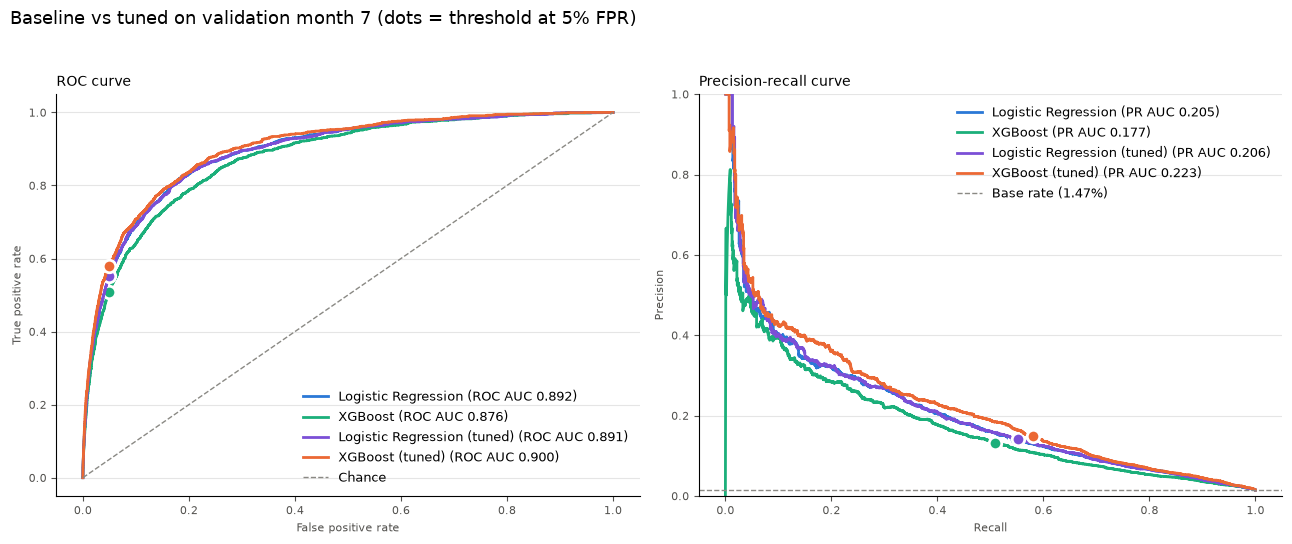

In [9]:
plot_roc_pr(list(val_scores), f"Baseline vs tuned on validation month 7 (dots = threshold at {TARGET_FPR:.0%} FPR)")
plot.show()

In this run (10 search trials per model in `03`):

- Tuning helped XGBoost the most: recall at 5% FPR rose from 50.8% to 58.0%, ROC AUC from 0.876 to 0.900 and PR AUC from 0.177 to 0.223, making tuned XGBoost the best model overall.
- Logistic regression barely moved (recall 54.7% to 55.2%, PR AUC 0.205 to 0.206), so it was already close to what a linear model can get from these features.
- Every model flags non-fraud applicants aged 50+ about three times as often as younger ones (FPR ~12% vs ~4%, predictive equality ~0.32-0.33), which motivates the age analysis below.

## Removing Age as a Feature

`customer_age` is the protected attribute, so both tuned models are retrained without it and compared with the tuned models that use it. The tuned hyperparameters are kept as they are. XGBoost re-runs early stopping, so its tree count can change. Every model is evaluated at the same 5% FPR operating point.

Predictive equality is reported two ways:
- **< 50 vs >= 50:** the BAF paper's binary split, as in the results table above.
- **All age buckets:** FPR within each decade of `customer_age`, then the lowest bucket FPR divided by the highest. 80+ (90s merged in) has under 100 non-fraud validation rows, so its FPR is noisy; the plot shows 95% Wilson intervals.

Dropping the column doesn't remove age information. Other features carry some of it: `date_of_birth_distinct_emails_4w` has a Spearman correlation of -0.45 with age, `employment_status` CC applicants average 52 against 27-35 for the other levels, and `housing_status` varies by up to 15 years. Any remaining FPR gap across ages can come through these proxies, so the FPRs are measured rather than assumed.

**MLflow** (when `LOG_TO_MLFLOW = True`): each retrained model is logged as `<model> (tuned, no age)` with the same artifacts as the other runs. An `Age removal fairness comparison` run holds the with/without-age metric table, the FPR-by-bucket table and plot, and the change in each metric when age is removed.

### MLflow Logging

Only used when `LOG_TO_MLFLOW = True`. `log_model_run` logs a model with its parameters, validation metrics, ROC/PR and confusion-matrix plots, classification report, FPR by age bucket and the model artifact, the same way as in `03_hyperparameter_tuning`.

In [10]:
if LOG_TO_MLFLOW:
    mlflow.set_tracking_uri("http://localhost:5000")
    mlflow.set_experiment("BAF account creation fraud detection")

# MLflow metric names can't contain characters like < or >=
METRIC_NAMES = {
    "ROC AUC": "roc_auc",
    "PR AUC": "pr_auc",
    "Precision": "precision",
    "Recall": "recall",
    "TPR": "tpr",
    "FPR": "fpr",
    f"FPR age < {AGE_GROUP_CUTOFF}": f"fpr_age_under_{AGE_GROUP_CUTOFF}",
    f"FPR age >= {AGE_GROUP_CUTOFF}": f"fpr_age_{AGE_GROUP_CUTOFF}_plus",
    "Predictive equality": "predictive_equality",
    "Predictive equality (all ages)": "predictive_equality_all_ages",
}
AGE_BUCKET_METRIC_NAMES = {label: "fpr_age_" + label.replace("-", "_").replace("+", "_plus")
                           for label in AGE_BUCKET_LABELS.values()}
CLASS_NAMES = ["Non-Fraud", "Fraud"]


# Served requests arrive as JSON, so XGBoost's categorical columns come in as strings.
# Logging the model behind this cast restores the training categories before predicting.
XGB_CATEGORY_DTYPES = {col: X_train_xgb[col].dtype for col in X_train_xgb.select_dtypes("category").columns}


def restore_categories(X):
    return X.astype(XGB_CATEGORY_DTYPES)


def log_model_run(name, model, X_val_model, serving_model=None, run_name=None, params=None, extra_params=None):
    if serving_model is None:
        serving_model = model
    if run_name is None:
        run_name = f"{name} baseline"
    if params is None:
        params = model.get_params()

    row = results.loc[name]
    y_pred = (val_scores[name] >= row["Threshold"]).astype(int)
    report = classification_report(y_val_array, y_pred, target_names=CLASS_NAMES, digits=4)
    age_fpr = fpr_by_age_bucket(y_val_array, y_pred, val_age)

    run_params = {
        "train_months": train_months,
        "val_months": val_months,
        "n_features": X_val_model.shape[1],
        "target_fpr": TARGET_FPR,
        "decision_threshold": row["Threshold"],
    }
    if extra_params:
        run_params.update(extra_params)

    metrics = {metric: row[column] for column, metric in METRIC_NAMES.items()}
    for bucket, fpr in age_fpr["fpr"].items():
        metrics[AGE_BUCKET_METRIC_NAMES[bucket]] = fpr

    if LOG_TO_MLFLOW:
        with mlflow.start_run(run_name=run_name):
            mlflow.log_params(params)
            mlflow.log_params(run_params)
            mlflow.log_metrics(metrics)

            fig = plot_roc_pr([name], f"{name} on validation month 7 (dot = threshold at {TARGET_FPR:.0%} FPR)")
            mlflow.log_figure(fig, "roc_pr_curves.png")
            plot.close(fig)

            fig, ax = plot.subplots(figsize=(5, 4.5))
            ConfusionMatrixDisplay.from_predictions(y_val_array, y_pred, display_labels=CLASS_NAMES,
                                                    cmap="Blues", colorbar=False, values_format=",", ax=ax)
            ax.set_title(f"{name} at {TARGET_FPR:.0%} FPR threshold", fontsize=10, loc="left")
            fig.tight_layout()
            mlflow.log_figure(fig, "confusion_matrix.png")
            plot.close(fig)

            mlflow.log_text(report, "classification_report.txt")
            mlflow.log_text(age_fpr.to_csv(), "fpr_by_age_bucket.csv")

            input_example = X_val_model.head(5)
            signature = infer_signature(input_example, serving_model.predict_proba(input_example))
            mlflow.sklearn.log_model(serving_model, name="model", signature=signature, input_example=input_example,
                                     pyfunc_predict_fn="predict_proba")

    print(f"{name} (threshold {row['Threshold']:.4f})")
    print(report)

### Retrain Without Age

Every LR preprocessing step works column by column (scaling, log, median fill, one-hot), so dropping the already-scaled `customer_age` column gives exactly the features a preprocessor refitted without age would produce.

In [11]:
AGE_COLS = ["customer_age"]
AGE_COMPARISON_MODELS = [
    "Logistic Regression (tuned)", "Logistic Regression (tuned, no age)",
    "XGBoost (tuned)", "XGBoost (tuned, no age)",
]

X_train_lr_no_age, X_val_lr_no_age = X_train_lr.drop(columns=AGE_COLS), X_val_lr.drop(columns=AGE_COLS)
X_train_xgb_no_age, X_val_xgb_no_age = X_train_xgb.drop(columns=AGE_COLS), X_val_xgb.drop(columns=AGE_COLS)


def add_model(name, model, X_val_model):
    # Score a new model and add it to the results so plots and tables pick it up
    models[name] = model
    model_val_inputs[name] = X_val_model
    val_scores[name] = model.predict_proba(X_val_model)[:, 1]
    results.loc[name] = pd.Series(evaluate_model(y_val_array, val_scores[name], val_age))


print(X_train_lr_no_age.shape, X_val_lr_no_age.shape)
print(X_train_xgb_no_age.shape, X_val_xgb_no_age.shape)

(903157, 49) (96843, 49)
(903157, 32) (96843, 32)


The tuned logistic regression is cloned with its fitted settings (including the rescaled `C` and weights for `saga`), then refitted without age.

In [12]:
lr_tuned = models["Logistic Regression (tuned)"]
lr_no_age = clone(lr_tuned).fit(X_train_lr_no_age, y_train)
add_model("Logistic Regression (tuned, no age)", lr_no_age, X_val_lr_no_age)

lr_summary = tuning_summary["lr_tuned"]
# C and class_weight logged as sampled, with the values saga was fitted with alongside (as in 03)
log_model_run(
    "Logistic Regression (tuned, no age)", lr_no_age, X_val_lr_no_age,
    run_name="Logistic Regression (tuned, no age)",
    params={**lr_no_age.get_params(), **lr_summary["params"],
            "saga_C": lr_no_age.C, "saga_class_weight": lr_no_age.class_weight},
    extra_params={"dropped_features": AGE_COLS, "hyperparameters_from": "Logistic Regression (tuned)",
                  "best_trial": lr_summary["best_trial"], "search_run_id": lr_summary["search_run_id"]},
)

Logistic Regression (tuned, no age) (threshold 0.0340)
              precision    recall  f1-score   support

   Non-Fraud     0.9929    0.9500    0.9710     95415
       Fraud     0.1399    0.5434    0.2225      1428

    accuracy                         0.9440     96843
   macro avg     0.5664    0.7467    0.5968     96843
weighted avg     0.9803    0.9440    0.9599     96843



XGBoost keeps its tuned hyperparameters but re-runs early stopping on the validation month, so its tree count can change.

In [13]:
xgb_tuned = models["XGBoost (tuned)"]
xgb_no_age = clone(xgb_tuned).set_params(device=XGB_DEVICE)
xgb_no_age.fit(X_train_xgb_no_age, y_train, eval_set=[(X_val_xgb_no_age, y_val)], verbose=False)
# Predict on the CPU, where the pandas input lives, and so the logged model doesn't need a GPU
xgb_no_age.set_params(device="cpu")
add_model("XGBoost (tuned, no age)", xgb_no_age, X_val_xgb_no_age)
print(f"Trees: {xgb_tuned.best_iteration + 1} with age, {xgb_no_age.best_iteration + 1} without")

xgb_summary = tuning_summary["xgb_tuned"]
log_model_run(
    "XGBoost (tuned, no age)", xgb_no_age, X_val_xgb_no_age,
    run_name="XGBoost (tuned, no age)",
    serving_model=make_pipeline(FunctionTransformer(restore_categories), xgb_no_age),
    extra_params={
        "best_iteration": xgb_no_age.best_iteration,
        "train_device": XGB_DEVICE,
        "dropped_features": AGE_COLS,
        "hyperparameters_from": "XGBoost (tuned)",
        "best_trial": xgb_summary["best_trial"],
        "search_run_id": xgb_summary["search_run_id"],
    },
)

Trees: 283 with age, 264 without
XGBoost (tuned, no age) (threshold 0.2956)
              precision    recall  f1-score   support

   Non-Fraud     0.9933    0.9502    0.9713     95415
       Fraud     0.1466    0.5721    0.2334      1428

    accuracy                         0.9446     96843
   macro avg     0.5700    0.7611    0.6023     96843
weighted avg     0.9808    0.9446    0.9604     96843



### With vs Without Age

Performance and the two predictive equality measures for each tuned model, with and without `customer_age`.

In [14]:
FAIRNESS_COLUMNS = [
    "ROC AUC", "PR AUC", "Recall", f"FPR age < {AGE_GROUP_CUTOFF}", f"FPR age >= {AGE_GROUP_CUTOFF}",
    "Predictive equality", "Predictive equality (all ages)",
]
age_metric_comparison = results.loc[AGE_COMPARISON_MODELS, FAIRNESS_COLUMNS].astype(float)
age_metric_comparison.round(4)

,ROC AUC,PR AUC,Recall,FPR age < 50,FPR age >= 50,Predictive equality,Predictive equality (all ages)
Logistic Regression (tuned),0.8913,0.2064,0.5518,0.0396,0.1191,0.3328,0.0359
"Logistic Regression (tuned, no age)",0.8908,0.2016,0.5434,0.0429,0.0979,0.4387,0.1372
XGBoost (tuned),0.8998,0.2228,0.5798,0.0390,0.1214,0.3216,0.0436
"XGBoost (tuned, no age)",0.8972,0.2184,0.5721,0.0427,0.0983,0.4345,0.1314


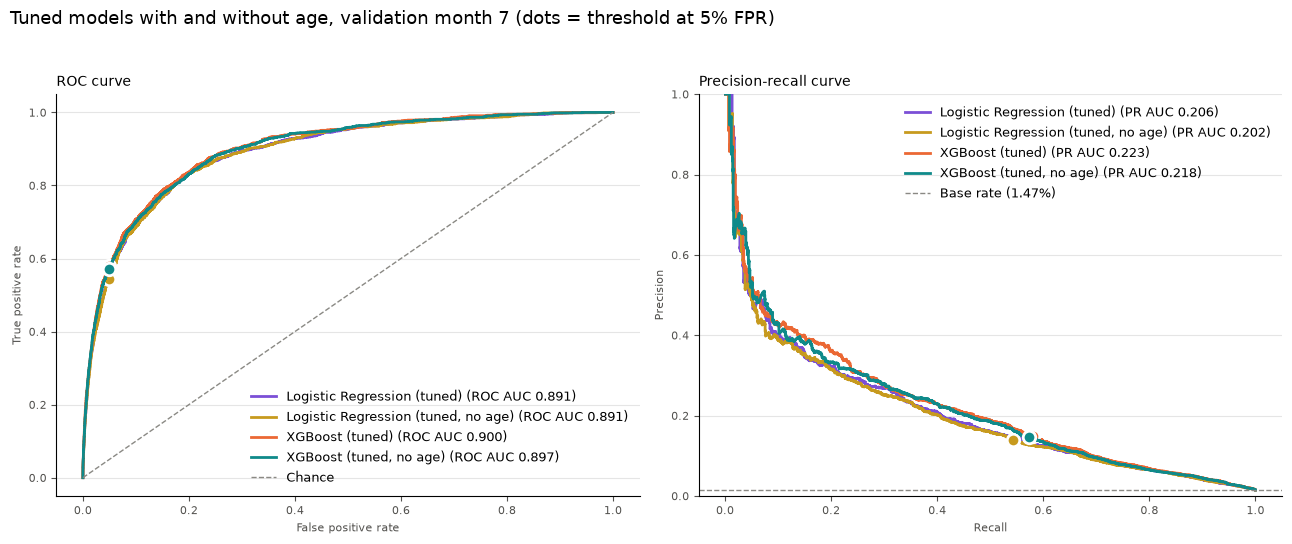

In [15]:
plot_roc_pr(AGE_COMPARISON_MODELS,
            f"Tuned models with and without age, validation month 7 (dots = threshold at {TARGET_FPR:.0%} FPR)")
plot.show()

- Removing age costs little performance: recall drops by under 1 point for both models (LR 55.2% to 54.3%, XGBoost 58.0% to 57.2%), and ROC AUC by 0.001-0.003.
- The FPR gap narrows: for applicants aged 50+ it falls from ~12% to ~10%, while under-50s rise slightly from ~3.9% to ~4.3%. Predictive equality improves from ~0.33 to ~0.44 for both models.
- It is still far from parity: older applicants are wrongly flagged over twice as often, since the age proxies described above remain in the data.

### FPR by Age Bucket

How the share of non-fraud applicants wrongly flagged varies with age, for each model, alongside how many validation rows fall in each bucket.

In [16]:
val_age_buckets = pd.Series(np.minimum(val_age, AGE_BUCKET_CAP)).map(AGE_BUCKET_LABELS)
age_population = pd.DataFrame({
    "Rows": val_age_buckets.value_counts(),
    "Non-fraud rows": val_age_buckets[y_val_array == 0].value_counts(),
}).reindex(list(AGE_BUCKET_LABELS.values())).rename_axis("age_bucket")
age_population.insert(1, "Share of rows", age_population["Rows"] / len(val_age_buckets))

age_fpr_tables = {}
for name in AGE_COMPARISON_MODELS:
    flagged = (val_scores[name] >= results.loc[name, "Threshold"]).astype(int)
    age_fpr_tables[name] = fpr_by_age_bucket(y_val_array, flagged, val_age)

fpr_by_model = pd.DataFrame({name: table["fpr"] for name, table in age_fpr_tables.items()})
age_fpr_comparison = age_population.join(fpr_by_model)
age_fpr_comparison.round(4)

,Rows,Share of rows,Non-fraud rows,Logistic Regression (tuned),"Logistic Regression (tuned, no age)",XGBoost (tuned),"XGBoost (tuned, no age)"
age_bucket,,,,,,,
10-19,2930,0.0303,2917,0.0096,0.0213,0.0117,0.0185
20-29,21023,0.2171,20867,0.0146,0.0220,0.0172,0.0219
30-39,32363,0.3342,31958,0.0351,0.0404,0.0385,0.0404
40-49,27860,0.2877,27424,0.0672,0.0642,0.0593,0.0637
50-59,9725,0.1004,9469,0.1116,0.0948,0.1088,0.0933
60-69,2501,0.0258,2370,0.1367,0.1080,0.1608,0.1156
70-79,364,0.0038,339,0.1740,0.1003,0.1681,0.1091
80+,77,0.0008,71,0.2676,0.1549,0.2676,0.1408


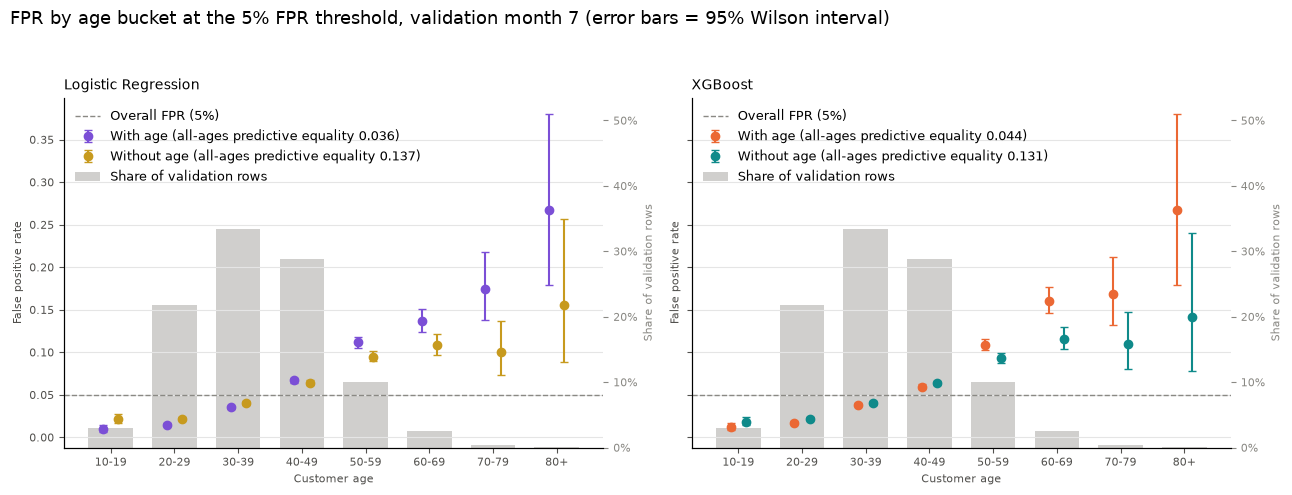

In [17]:
def wilson_interval(successes, n, z=1.96):
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half_width, centre + half_width


def plot_fpr_by_age(families):
    fig, axes = plot.subplots(1, len(families), figsize=(6.5 * len(families), 5), sharey=True)
    x = np.arange(len(AGE_BUCKET_LABELS))

    for ax, family in zip(np.atleast_1d(axes), families):
        # Share of all validation rows in each bucket, drawn on a second axis behind the FPR points
        share_ax = ax.twinx()
        share_ax.bar(x, age_population["Share of rows"], width=0.7, color=REFERENCE_COLOR, alpha=0.4,
                     label="Share of validation rows")
        share_ax.set_ylim(0, age_population["Share of rows"].max() * 1.6)
        share_ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
        share_ax.tick_params(labelsize=8, colors=REFERENCE_COLOR)
        share_ax.set_ylabel("Share of validation rows", fontsize=8, color=REFERENCE_COLOR)
        share_ax.spines[["top", "right"]].set_visible(False)
        ax.set_zorder(share_ax.get_zorder() + 1)
        ax.patch.set_visible(False)

        # With- and without-age points sit either side of each tick
        model_variants = [
            (-0.12, f"{family} (tuned)", "With age"),
            (0.12, f"{family} (tuned, no age)", "Without age"),
        ]
        for offset, name, label in model_variants:
            table = age_fpr_tables[name]
            low, high = wilson_interval(table["false_positives"], table["non_fraud"])
            error = [table["fpr"] - low, high - table["fpr"]]
            equality = results.loc[name, "Predictive equality (all ages)"]
            ax.errorbar(x + offset, table["fpr"], yerr=error, fmt="o", color=MODEL_COLORS[name], markersize=6,
                        capsize=3, linewidth=1.5, label=f"{label} (all-ages predictive equality {equality:.3f})")

        ax.axhline(TARGET_FPR, linestyle="--", linewidth=1, color=REFERENCE_COLOR,
                   label=f"Overall FPR ({TARGET_FPR:.0%})")
        ax.set_xticks(x)
        ax.set_xticklabels(AGE_BUCKET_LABELS.values())
        style_axis(ax, family, "False positive rate")
        ax.set_xlabel("Customer age", fontsize=8, color="#52514e")

        handles, labels = ax.get_legend_handles_labels()
        share_handles, share_labels = share_ax.get_legend_handles_labels()
        ax.legend(handles + share_handles, labels + share_labels, loc="upper left", frameon=False, fontsize=9)

    title = (f"FPR by age bucket at the {TARGET_FPR:.0%} FPR threshold, validation month 7 "
             "(error bars = 95% Wilson interval)")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig


age_fpr_fig = plot_fpr_by_age(["Logistic Regression", "XGBoost"])
plot.show()

- FPR rises steadily with age for every model, from 1-2% for teenagers to over 10% from the 60s up.
- Without age, the older buckets fall the most (e.g. LR 70-79: 17.4% to 10.0%) and the youngest rise slightly (LR 10-19: 1.0% to 2.1%), so the curve flattens but keeps its shape.
- All-ages predictive equality improves from ~0.04 to ~0.13, but it is driven by the extreme buckets: 80+ has only 71 non-fraud rows and 70-79 has 339, so their intervals are wide. Most applicants are aged 20-49, where the with/without-age differences are small.

In [18]:
if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name="Age removal fairness comparison"):
        mlflow.log_params({
            "dropped_features": AGE_COLS,
            "models": AGE_COMPARISON_MODELS,
            "age_bucket_cap": AGE_BUCKET_CAP,
            "target_fpr": TARGET_FPR,
            "val_months": val_months,
        })
        for family in ("Logistic Regression", "XGBoost"):
            with_age = age_metric_comparison.loc[f"{family} (tuned)"]
            without_age = age_metric_comparison.loc[f"{family} (tuned, no age)"]
            change = without_age - with_age

            prefix = family.lower().replace(" ", "_")
            change_metrics = {f"{prefix}_{METRIC_NAMES[column]}_change": value for column, value in change.items()}
            mlflow.log_metrics(change_metrics)
        mlflow.log_text(age_metric_comparison.to_csv(), "metrics_comparison.csv")
        mlflow.log_text(age_fpr_comparison.to_csv(), "fpr_by_age_bucket.csv")
        mlflow.log_figure(age_fpr_fig, "fpr_by_age_bucket.png")